## 다음 영화 리뷰 데이터 분석
1. 데이터 로딩
2. 텍스트 전처리
3. 빈도수 계산
4. 시각화

In [2]:
# 데이터 로딩
datafile = "data/daum_movie_review.csv"

import pandas as pd
df = pd.read_csv(datafile)

In [3]:
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  14725 non-null  object
 1   rating  14725 non-null  int64 
 2   date    14725 non-null  object
 3   title   14725 non-null  object
dtypes: int64(1), object(3)
memory usage: 460.3+ KB


In [6]:
# 품사 태깅 -> 토큰화, 불용어제거
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review)

pos_list = []
for review in reviews:
    tokens = tagger.pos(review)
    pos_list.append(tokens)
len(pos_list)

14725

In [7]:
pos_list[:5]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')],
 [('몰입', 'Noun'),
  ('할수밖에', 'Verb'),
  ('없다', 'Adjective'),
  ('.', 'Punctuation'),
  ('어렵게', 'Adjective'),
  ('생각', 'Noun'),
  ('할', 'Verb'),
  ('필요없다', 'Adjective'),
  ('.', 'Punctuation'),
  ('내', 'Noun'),
  ('가', 'Josa'),
  ('전투', 'Noun'),
  ('에', 'Josa'),
  ('참여', 'Noun'),
  ('한', 'Determiner'),
  ('듯', 'Noun'),
  ('손', 'Noun'),
  ('에', 'Josa'),
  ('땀', 'Noun'),
  ('이남', 'Noun'),
  ('.', 'Punctuation')],
 [('이전', 'Noun'),
  ('작품', 'Noun'),
  ('에', 'Josa'),
  ('비해', 'Verb'),
  ('더', 'Noun'),
  ('화려하고', 'Adjective'),
  ('스케일', 'Noun'),
  ('도', 'Josa'),
  ('커졌지만', 'Verb'),
  ('....', 'Punctuation'),
  ('전국', 'Noun'),
  ('맛집', 'Noun'),
  ('의', 'Josa'),
  ('음식', 'Noun'),
  ('들', 'Suffix'),
  ('을', 'Josa'),
  ('한데', 'Eomi'),
  ('모은', 'Verb'),
  ('것', 'Noun'),
  ('까지는', 'Josa'),
  ('좋았으나', 'Adjective'),
  ('이', '

In [12]:
# 불용어 제거 -> 필요한 품사의 단어만 추출
my_tags = ['Noun', 'Verb', 'Adjective']
my_stopwords = ['영화', '것', '이', '더']


result_list = []
for review in pos_list:
    for word, tag in review:
        if tag in my_tags and word not in my_stopwords:
            result_list.append(word)

result_list[:10]

['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [13]:
# 빈도수 계산 -> Counter 객체를 생성하여 사용
from collections import Counter

counter  = Counter(result_list)
count_list = counter.most_common(20)
print(count_list)

[('연기', 1293), ('감동', 1223), ('생각', 1027), ('정말', 948), ('배우', 847), ('사람', 819), ('스토리', 815), ('진짜', 781), ('잘', 776), ('하는', 770), ('눈물', 737), ('보고', 709), ('점', 692), ('최고', 682), ('좀', 671), ('재미', 641), ('마지막', 612), ('그', 610), ('시간', 596), ('입니다', 580)]


In [27]:
# matplotlib 한글 폰트 설정
import matplotlib.pyplot as plt
font_path = 'C:/Windows/Fonts/malgun.ttf'

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

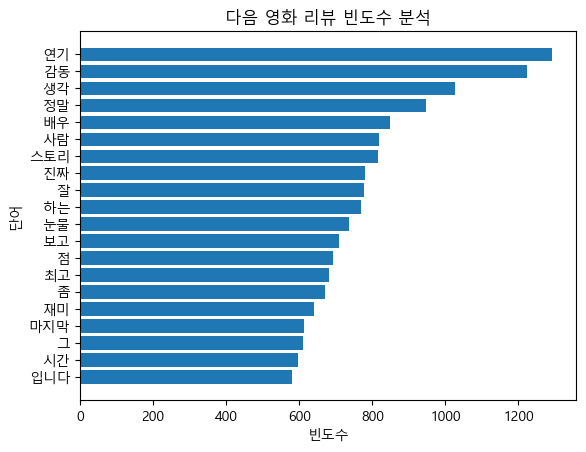

In [28]:
# 시각화 - 수평 막대 그래프


# (1) 데이터 준비
x = [word for word, count in count_list]
y = [count for word, count in count_list]

#x = [], y = []
#for word, count in count_list:
#    x.append(word)
#    y.append(count)


# (2) 그래프 생성
plt.barh(x[::-1], y[::-1])

#(3)필요 정보 추가
plt.title("다음 영화 리뷰 빈도수 분석")
plt.xlabel('빈도수')
plt.ylabel('단어')

#(4) 출력
#plt.show()
plt.savefig('result/daum_movie_review_graph.jpg')